# XP GOLD

## How to run in Colab
1. I open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** and choose this file.
2. I keep the course dataset zip **`Students Performance.zip`** in my `C:\Users\sivan\Datasets` folder (I don't unzip it myself).
3. I run the cells from top to bottom. When the upload cell opens a file picker, I choose `Students Performance.zip`. The next line unzips it and gives me **`Students Performance.csv`**.

The template calls the data "StudentsPerformance"; the real course file is `Students Performance.csv` (with a space), so I load that name.

**Note:** the exercise instructions say to stop at **XP NINJA**. I left a comment there, and I still completed the One-way ANOVA part that follows in this same Gold notebook.

(If I run the notebook on my own computer instead of Colab, the upload step is skipped and the zip just needs to be in the same folder as the notebook.)

In [1]:
try:
    from google.colab import files
    uploaded = files.upload()  # Prompts user to select zip file
except ImportError:
    print("Not running in Colab: I use the zip that is already next to this notebook.")
!unzip -o "Students Performance.zip"     # Unzips uploaded dataset file

Not running in Colab: I use the zip that is already next to this notebook.
Archive:  Students Performance.zip
  inflating: Students Performance.csv  


 # Society's assumptions aren't always true... aren't they?




We begin by loading the libraries needed for this project.

In [2]:
import importlib
import sys
import matplotlib


def install_and_import(packages):
    """
    Attempts to import packages. If a package is missing, it prints a message instead of installing.
    """
    for package in packages:
        try:
            globals()[package] = importlib.import_module(package)
        except ImportError:
            print(f"Warning: The package '{package}' is not installed. Please install it manually.")


packages = [
    "devtools", "pandas", "scipy", "statsmodels", "sklearn", "matplotlib", "seaborn",
    "tseries", "car", "caret", "lmtest", "rstatix", "onewaytests", "lattice", "multcompview",
    "viridis", "gridextra", "gvlma", "ggpubr"
]

install_and_import(packages)

# Now all available libraries are imported


Now we can load the dataset

In [3]:
## TODO: Load the "StudentsPerformance" dataset from a CSV file.
# The course zip gives me the file "Students Performance.csv" (with a space), which I unzipped above.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import lilliefors, normal_ad

StudentsPerformance = pd.read_csv('Students Performance.csv')
print(StudentsPerformance.shape)
StudentsPerformance.head()

(1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### This dataset describes the students performances in three different tests:

- **Math**

- **Reading**

- **Writing**

### Through different variables:

- **gender** : binary sex at birth for each individual

- **race.ethnicity** : ethnicity group

- **parental.level.of.education** : formal level of education achieved by the individual

- **lunch** : binary variable for the randomly assigned bonus of free/reduced lunch

- **test.preparation.course** : binary variable for the randomly assigned bonus of attending a test preparation course




# Which 'gender' is better at maths? And which is better in writing and reading?

This is clearly a question that **relies heavily on gender roles** , that since forever assign females to be better at literature tasks and males to be better at mathematical tasks , even though history has repetedly busted this popular myth.

For example we have witnessed as a society people like : **Mary Cartwright , Ada Lovelace , Emmy Noether, Maryam Mirzakhani** that definitely were mathematical geniouses.

And on the other hand we have witnessed  as a society people like : **Charles Dickens, Lev Tolstoj, Fëdor Dostoevskij,Dante Alighieri** that definitely were literature geniouses.

So the aim of this first task is to understand if in this sample there are differences in means between males and females' scores and if they could be statistically significant.

### Before conducting any test , let's visualize the situation

We're going to do some data wrangling to visualize the scores by gender

In [4]:
## TODO: Transform the dataset by selecting gender and scores, then pivot the scores into long format.
gender_scores_long = StudentsPerformance[['gender', 'math score', 'reading score', 'writing score']].melt(
    id_vars='gender', var_name='test', value_name='score')
print(gender_scores_long.shape)   # 1000 students x 3 tests = 3000 rows
gender_scores_long.head()

(3000, 3)


,gender,test,score
0,female,math score,72
1,female,math score,69
2,female,math score,90
3,male,math score,47
4,male,math score,76


### Now we can finally plot the differences between genders in the scores


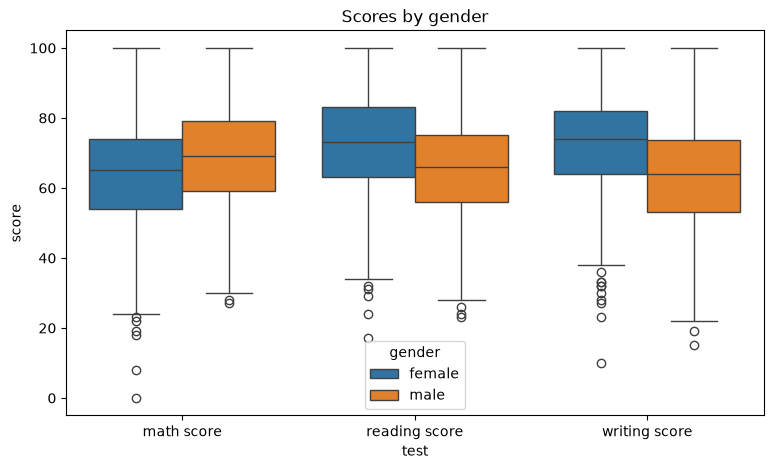

gender         female   male
test                        
math score      63.63  68.73
reading score   72.61  65.47
writing score   72.47  63.31


In [5]:
## TODO: Create a boxplot comparing scores by gender
plt.figure(figsize=(9, 5))
sns.boxplot(data=gender_scores_long, x='test', y='score', hue='gender')
plt.title('Scores by gender')
plt.show()

# The mean score of each gender for each test:
print(gender_scores_long.groupby(['test', 'gender'])['score'].mean().unstack().round(2))

It looks like:

- **For math score**: males are a little bit better

- **For reading score**: females are a little bit better

- **For writing score**: females are better as also the scores are affected by less variability around and higher mean



***



# Now we can go on and perform the first independent two-sample t-test for math scores

The size of the males and females samples are different!

This means that in the equation for the t statistic:

$$ t = \frac{\bar{x_{1}}-\bar{x_{2}}}{S_{pool}\sqrt{\frac{1}{n_{1}}-\frac{1}{n_{2}}}} $$
happens that:

$$n_{1}\neq n_{2}$$


First we perform some data wrangling on the main dataframe

In [6]:
## TODO: Reshape the data into a tidy format
# Tidy format: one row = one student and one test, with all the student's information kept.
tidy_StudentsPerformance = StudentsPerformance.melt(
    id_vars=['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course'],
    value_vars=['math score', 'reading score', 'writing score'],
    var_name='test', value_name='score')
print(tidy_StudentsPerformance.shape)
tidy_StudentsPerformance.head()

(3000, 7)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,test,score
0,female,group B,bachelor's degree,standard,none,math score,72
1,female,group C,some college,standard,completed,math score,69
2,female,group B,master's degree,standard,none,math score,90
3,male,group A,associate's degree,free/reduced,none,math score,47
4,male,group C,some college,standard,none,math score,76


We take male and females groups for the math scores:


In [7]:
## TODO: Separate the scores for males and females in math by filtering the data accordingly.
math_rows = tidy_StudentsPerformance[tidy_StudentsPerformance['test'] == 'math score']
Males_Math = math_rows.loc[math_rows['gender'] == 'male', 'score']
Females_Math = math_rows.loc[math_rows['gender'] == 'female', 'score']
print(f"Males: n = {len(Males_Math)}, mean = {Males_Math.mean():.2f}")
print(f"Females: n = {len(Females_Math)}, mean = {Females_Math.mean():.2f}")

Males: n = 482, mean = 68.73
Females: n = 518, mean = 63.63



### Now we are able to go on and check the t- test assumptions:

Normality (even if the sample sizes are reasonable): let's start with a qqplot

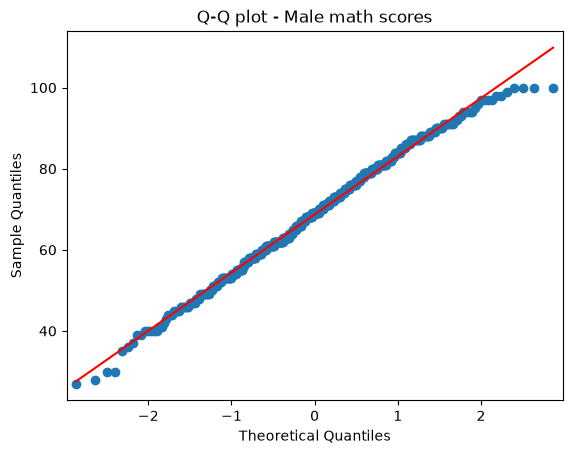

In [8]:
## TODO: Create a plot for the male math scores.
# A Q-Q plot: if the points follow the red line, the scores look normally distributed.
sm.qqplot(Males_Math, line='s')
plt.title('Q-Q plot - Male math scores')
plt.show()


</br>
</br>
</br>

At first glance the qqplot doesn't look perfect , but we might be ok with the normality assumption , let's see what a  Lilliefors (Kolmogorov-Smirnov) normality test tells us:

In [9]:
## TODO: Perform a Lilliefors (Kolmogorov-Smirnov) test for normality on the male math scores.
# H0: the scores come from a normal distribution.
ks_stat, p_value_lillie_male_math = lilliefors(Males_Math, dist='norm')
print(f"Lilliefors statistic = {ks_stat:.4f}, p-value = {p_value_lillie_male_math:.4f}")

Lilliefors statistic = 0.0388, p-value = 0.1031


at significance level 0.05 normality assumption is checked since the p-value is 0.08.


### Let's check for the females group:

> **My note:** in my run the Lilliefors p-value is **0.1031** (the text above says 0.08). It is still above 0.05, so I keep the normality assumption for the male math scores.

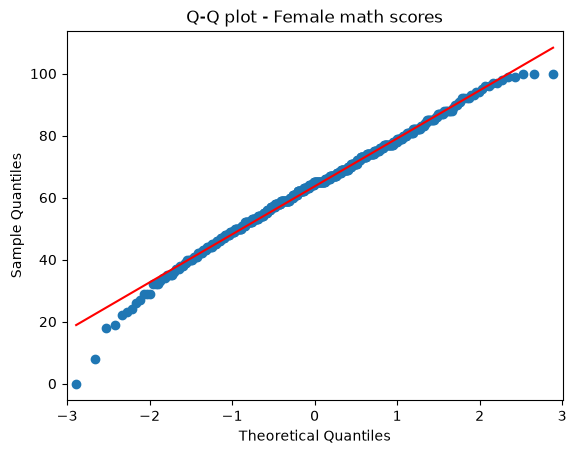

In [10]:
## TODO: Create a plot for the female math scores to check for normality.
sm.qqplot(Females_Math, line='s')
plt.title('Q-Q plot - Female math scores')
plt.show()


</br>
</br>
</br>

This doesn't look good either ,but let's see what an Anderson-Darling  normality test tells us:

In [11]:
## TODO: Perform the Anderson-Darling test on the female math scores to check for normality.
# statsmodels' normal_ad gives the Anderson-Darling statistic AND a p-value (scipy's version only gives critical values).
ad_stat, p_value_ad_female_math = normal_ad(Females_Math)
print(f"Anderson-Darling statistic = {ad_stat:.4f}, p-value = {p_value_ad_female_math:.4f}")

Anderson-Darling statistic = 0.7059, p-value = 0.0650


at significance level 0.05 normality assumption is checked since the p-value is 0.065.


### Let's test homoschedasticity (sample size is different for each group):

> **My note:** my Anderson-Darling result matches: statistic = 0.7059, **p = 0.0650** > 0.05, so I keep normality for the female math scores.

In [12]:
## TODO: Calculate the ratio of the variance between male and female math scores in both directions.
var_male_math = Males_Math.var()
var_female_math = Females_Math.var()
print(f"Variance: males = {var_male_math:.2f}, females = {var_female_math:.2f}")
print(f"Ratio male/female = {var_male_math / var_female_math:.3f}")
print(f"Ratio female/male = {var_female_math / var_male_math:.3f}")

Variance: males = 206.10, females = 239.99
Ratio male/female = 0.859
Ratio female/male = 1.164


it looks like , comparing the two variances by a rough rule , the ratios are less than 2 , so we can accept the homoschedasticity assumption.

Let's remove outliers

> **My note:** my ratios are 0.859 (male/female) and 1.164 (female/male), both below 2. Variances: males 206.10, females 239.99.

In [13]:
## TODO: Remove outliers from male and female math scores using the IQR method and filter them out of the dataset.

def remove_outliers_iqr(scores):
    """I keep only the scores between Q1 - 1.5*IQR and Q3 + 1.5*IQR."""
    q1 = scores.quantile(0.25)
    q3 = scores.quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    return scores[(scores >= lower_limit) & (scores <= upper_limit)]

Males_Math_before, Females_Math_before = len(Males_Math), len(Females_Math)
Males_Math = remove_outliers_iqr(Males_Math)
Females_Math = remove_outliers_iqr(Females_Math)
print(f"Males_Math: removed {Males_Math_before - len(Males_Math)} outliers, {len(Males_Math)} scores left")
print(f"Females_Math: removed {Females_Math_before - len(Females_Math)} outliers, {len(Females_Math)} scores left")

Males_Math: removed 2 outliers, 480 scores left
Females_Math: removed 6 outliers, 512 scores left


### Now we can finally perform our two sample t-test

### Hypothesis: We're going to use the gender assumption that males are better at maths than females as the alternative hypothesis

$$
H_{0} : \mu_{MaleMaths}\leq \mu_{FemaleMaths}
$$

$$
H_{A} : \mu_{MaleMaths} >  \mu_{FemaleMaths}
$$

In [14]:
## TODO: Perform a t-test to compare male and female math scores, testing if males have significantly greater scores.
# One-sided test: H_A says males > females. I use equal_var=True because the variance ratio was below 2.
t_stat_math, p_value_math = stats.ttest_ind(Males_Math, Females_Math, equal_var=True, alternative='greater')
print(f"Mean math: males = {Males_Math.mean():.2f}, females = {Females_Math.mean():.2f}")
print(f"t = {t_stat_math:.4f}, p-value = {p_value_math:.3e}")
print("Reject H0" if p_value_math < 0.05 else "Fail to reject H0", "at alpha = 0.05")

Mean math: males = 68.90, females = 64.20
t = 5.1372, p-value = 1.679e-07
Reject H0 at alpha = 0.05


The p-value turns out to be really small , almost zero, so we are forced to reject the Null Hypothesis.

**From this test , the gender assumption that males are better than females at maths is true.**



***



# Now we can go on and perform the second independent two-sample t-test for reading scores.

We take male and females groups for the reading scores:

> **My note:** after removing the outliers (2 male and 6 female scores), males average **68.90** and females **64.20** in math. One-sided t-test: t = 5.14, **p = 1.68e-07**, far below 0.05, so I reject H0. To be careful: this means that *in this sample* male students scored significantly higher in math on average (about 4.7 points). It does not prove that one gender is "naturally" better.

In [15]:
## TODO: Extract the reading scores for males and females from the tidy_StudentsPerformance dataset.
reading_rows = tidy_StudentsPerformance[tidy_StudentsPerformance['test'] == 'reading score']
Males_Reading = reading_rows.loc[reading_rows['gender'] == 'male', 'score']
Females_Reading = reading_rows.loc[reading_rows['gender'] == 'female', 'score']
print(f"Males: n = {len(Males_Reading)}, mean = {Males_Reading.mean():.2f}")
print(f"Females: n = {len(Females_Reading)}, mean = {Females_Reading.mean():.2f}")

Males: n = 482, mean = 65.47
Females: n = 518, mean = 72.61



### Now we are able to go on and check the t- test assumptions:

Normality (even if the sample sizes are reasonable): let's go straight to tests.

In [16]:
## TODO: Perform the Cramer-Von Mises test on the Males_Reading scores.

# Cramer-Von Mises test. H0: the scores are normal (with the group's own mean and standard deviation).
cvm_result = stats.cramervonmises(Males_Reading, 'norm', args=(Males_Reading.mean(), Males_Reading.std()))
print(f"Males_Reading: CVM statistic = {cvm_result.statistic:.4f}, p-value = {cvm_result.pvalue:.4f}")

Males_Reading: CVM statistic = 0.0997, p-value = 0.5864


at significance level 0.05 normality assumption is checked since the p-value is 0.11.


### Let's check for the females group:

> **My note:** in my run the Cramer-Von Mises p-value for male reading is **0.5864** (the text says 0.11). Because I plug the sample's own mean and standard deviation into scipy's Cramer-Von Mises test, its p-value comes out higher (more generous) than the R-style test the template used. The conclusion is the same: normality is not rejected.

In [17]:
## TODO: Perform the Cramer-Von Mises test on the Females_Reading scores.

# Cramer-Von Mises test. H0: the scores are normal (with the group's own mean and standard deviation).
cvm_result = stats.cramervonmises(Females_Reading, 'norm', args=(Females_Reading.mean(), Females_Reading.std()))
print(f"Females_Reading: CVM statistic = {cvm_result.statistic:.4f}, p-value = {cvm_result.pvalue:.4f}")

Females_Reading: CVM statistic = 0.1157, p-value = 0.5136


at significance level 0.05 normality assumption is checked since the p-value is 0.068.


let's test homoschedasticity (sample size is different for each group):

> **My note:** in my run the Cramer-Von Mises p-value for female reading is **0.5136** (the text says 0.068). Because I plug the sample's own mean and standard deviation into scipy's Cramer-Von Mises test, its p-value comes out higher (more generous) than the R-style test the template used. The conclusion is the same: normality is not rejected.

In [18]:
## TODO: Calculate the ratio of variances between Males_Reading and Females_Reading scores.
var_male_reading = Males_Reading.var()
var_female_reading = Females_Reading.var()
print(f"Variance: males = {var_male_reading:.2f}, females = {var_female_reading:.2f}")
print(f"Ratio male/female = {var_male_reading / var_female_reading:.3f}")
print(f"Ratio female/male = {var_female_reading / var_male_reading:.3f}")

Variance: males = 194.10, females = 206.73
Ratio male/female = 0.939
Ratio female/male = 1.065


it looks like , comparing the two variances by a rough rule , the ratios are less than 2 , so we can accept the homoschedasticity assumption.

Let's remove outliers

> **My note:** my ratios are 0.939 (male/female) and 1.065 (female/male), both below 2. Variances: males 194.10, females 206.73.

In [19]:
## TODO: Remove outliers using the IQR method from both Males_Reading and Females_Reading scores.

def remove_outliers_iqr(scores):
    """I keep only the scores between Q1 - 1.5*IQR and Q3 + 1.5*IQR."""
    q1 = scores.quantile(0.25)
    q3 = scores.quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    return scores[(scores >= lower_limit) & (scores <= upper_limit)]

Males_Reading_before, Females_Reading_before = len(Males_Reading), len(Females_Reading)
Males_Reading = remove_outliers_iqr(Males_Reading)
Females_Reading = remove_outliers_iqr(Females_Reading)
print(f"Males_Reading: removed {Males_Reading_before - len(Males_Reading)} outliers, {len(Males_Reading)} scores left")
print(f"Females_Reading: removed {Females_Reading_before - len(Females_Reading)} outliers, {len(Females_Reading)} scores left")

Males_Reading: removed 3 outliers, 479 scores left
Females_Reading: removed 5 outliers, 513 scores left


### Now we can finally perform our two sample t-test

### Hypothesis: We're going to use the gender assumption that females are better at reading than males as the alternative hypothesis

$$H_{0} : \mu_{FemaleReading}\leq \mu_{MaleReading}$$

$$H_{A} : \mu_{FemaleReading} >  \mu_{MaleReading}$$

In [20]:
## TODO: Perform a t-test to compare Females_Reading and Males_Reading scores, testing if the mean score for females is greater.
t_stat_reading, p_value_reading = stats.ttest_ind(Females_Reading, Males_Reading, equal_var=True, alternative='greater')
print(f"Mean reading: females = {Females_Reading.mean():.2f}, males = {Males_Reading.mean():.2f}")
print(f"t = {t_stat_reading:.4f}, p-value = {p_value_reading:.3e}")
print("Reject H0" if p_value_reading < 0.05 else "Fail to reject H0", "at alpha = 0.05")

Mean reading: females = 73.06, males = 65.73
t = 8.4508, p-value = 5.119e-17
Reject H0 at alpha = 0.05


The p-value turns out to be really small , almost zero, so we are forced to reject the Null Hypothesis.

**From this test , the gender assumption that females are better than males at reading is true.**



***



# Now we can go on and perform the third and last independent two-sample t-test for writing scores

We take male and females groups for the writing scores:

> **My note:** after removing the outliers (3 male and 5 female scores), females average **73.06** and males **65.73** in reading. One-sided t-test: t = 8.45, **p = 5.12e-17** < 0.05, so I reject H0. In this sample female students scored significantly higher in reading on average (about 7.3 points).

In [21]:
## TODO: Create two separate dataframes, one for male and one for female writing scores.
writing_rows = tidy_StudentsPerformance[tidy_StudentsPerformance['test'] == 'writing score']
Males_Writing_df = writing_rows[writing_rows['gender'] == 'male']
Females_Writing_df = writing_rows[writing_rows['gender'] == 'female']
Males_Writing = Males_Writing_df['score']
Females_Writing = Females_Writing_df['score']
print(f"Males: n = {len(Males_Writing)}, mean = {Males_Writing.mean():.2f}")
print(f"Females: n = {len(Females_Writing)}, mean = {Females_Writing.mean():.2f}")

Males: n = 482, mean = 63.31
Females: n = 518, mean = 72.47



### Now we are able to go on and check the t- test assumptions:

- Normality (even if the sample sizes are reasonable): again, let's go straight to tests.


In [22]:
## TODO: Perform the Cramer-Von Mises test for the male writing scores.

# Cramer-Von Mises test. H0: the scores are normal (with the group's own mean and standard deviation).
cvm_result = stats.cramervonmises(Males_Writing, 'norm', args=(Males_Writing.mean(), Males_Writing.std()))
print(f"Males_Writing: CVM statistic = {cvm_result.statistic:.4f}, p-value = {cvm_result.pvalue:.4f}")

Males_Writing: CVM statistic = 0.1065, p-value = 0.5542


at significance level 0.05 normality assumption is checked since the p-value is 0.09.


### Let's check for the females group:

> **My note:** in my run the Cramer-Von Mises p-value for male writing is **0.5542** (the text says 0.09). Because I plug the sample's own mean and standard deviation into scipy's Cramer-Von Mises test, its p-value comes out higher (more generous) than the R-style test the template used. The conclusion is the same: normality is not rejected.

In [23]:
## TODO: Perform the Lilliefors test for the female writing scores.
ks_stat_fw, p_value_lillie_female_writing = lilliefors(Females_Writing, dist='norm')
print(f"Lilliefors statistic = {ks_stat_fw:.4f}, p-value = {p_value_lillie_female_writing:.4f}")

Lilliefors statistic = 0.0614, p-value = 0.0010


**It looks like the normality assumption is not verified here!**

### So let's try to transform data with box-cox transformation

> **My note:** I agree: the Lilliefors test on the female writing scores gives **p = 0.0010** < 0.05, so the female writing scores are not normal.

In [24]:
## TODO: Perform the Box-Cox transformation and apply the CVM test to the writing scores of both males and females.
# Box-Cox needs positive values (the lowest writing score is 10, so that is fine).
# I find ONE lambda on all writing scores together, and apply the same lambda to both groups,
# so the two groups are still measured on the same scale and can be compared in the t-test.
all_writing_boxcox, writing_lambda = stats.boxcox(writing_rows['score'])
print(f"Box-Cox lambda = {writing_lambda:.4f}")
Males_Writing_bc = pd.Series(stats.boxcox(Males_Writing, lmbda=writing_lambda), index=Males_Writing.index)
Females_Writing_bc = pd.Series(stats.boxcox(Females_Writing, lmbda=writing_lambda), index=Females_Writing.index)

for label, transformed in [('Males_Writing (Box-Cox)', Males_Writing_bc), ('Females_Writing (Box-Cox)', Females_Writing_bc)]:
    cvm_result = stats.cramervonmises(transformed, 'norm', args=(transformed.mean(), transformed.std()))
    print(f"{label}: CVM statistic = {cvm_result.statistic:.4f}, p-value = {cvm_result.pvalue:.4f}")

Box-Cox lambda = 1.3766
Males_Writing (Box-Cox): CVM statistic = 0.1132, p-value = 0.5243


Females_Writing (Box-Cox): CVM statistic = 0.0981, p-value = 0.5946


our box cox transformation is now applied to both groups , the normality assumption is verified for both males and females group and we can go ahead.



let's test homoschedasticity (sample size is different for each group):

> **My note:** I found one Box-Cox lambda (**1.3766**) on all writing scores and applied it to both groups, so they stay on the same scale. After the transformation the CVM p-values are **0.5243** (males) and **0.5946** (females), both above 0.05, so normality is OK for both groups.

In [25]:
## TODO: Calculate and compare the variance of writing scores for males and females.
var_male_writing = Males_Writing_bc.var()
var_female_writing = Females_Writing_bc.var()
print(f"Variance after Box-Cox: males = {var_male_writing:.2f}, females = {var_female_writing:.2f}")
print(f"Ratio male/female = {var_male_writing / var_female_writing:.3f}")
print(f"Ratio female/male = {var_female_writing / var_male_writing:.3f}")
print(f"(On the original scale: male/female = {Males_Writing.var() / Females_Writing.var():.3f})")

Variance after Box-Cox: males = 4434.14, females = 5257.97
Ratio male/female = 0.843
Ratio female/male = 1.186
(On the original scale: male/female = 0.904)


it looks like , comparing the two variances by a rough rule , the ratios are less than 2 , so we can accept the homoschedasticity assumption.



### Now we can finally perform our two sample t-test

### Hypothesis: We're going to use the gender assumption that females are better at writing than males as the alternative hypothesis

$$H_{0} : \mu_{FemaleWriting}\leq \mu_{MaleWriting}$$

$$H_{A} : \mu_{FemaleWriting} >  \mu_{MaleWriting}$$

> **My note:** after Box-Cox my variance ratios are 0.843 (male/female) and 1.186 (female/male), both below 2 (on the original scale the ratio is 0.904).

In [26]:
## TODO: Perform a t-test to compare Box-Cox transformed writing scores for males and females with the alternative hypothesis "greater".
t_stat_writing, p_value_writing = stats.ttest_ind(Females_Writing_bc, Males_Writing_bc, equal_var=True, alternative='greater')
print(f"Mean writing (original scale): females = {Females_Writing.mean():.2f}, males = {Males_Writing.mean():.2f}")
print(f"t = {t_stat_writing:.4f}, p-value = {p_value_writing:.3e}")
print("Reject H0" if p_value_writing < 0.05 else "Fail to reject H0", "at alpha = 0.05")

Mean writing (original scale): females = 72.47, males = 63.31
t = 10.1838, p-value = 1.531e-23
Reject H0 at alpha = 0.05


Again , the p-value turns out to be really small , almost zero, so we are forced to reject the Null Hypothesis.

**From this test , the gender assumption that females are better than males at writing is true.**

> **My note:** on the Box-Cox scale the one-sided t-test gives t = 10.18 and **p = 1.53e-23** < 0.05, so I reject H0. On the original scale females average **72.47** and males **63.31** in writing, about 9.2 points more. Like for math and reading, this is a result about this sample of students, not proof of a natural difference.
>
> **The course says to stop the XP Gold exercise here ("stop when you see XP Ninja"). I note that, but I still complete the One-way ANOVA section below, because it is part of this same Gold notebook.**

***

# XP NINJA

# One-way ANOVA

We are interested in understanding whether or not the **factor** ( in this case the treatments ) has an effect on the **outcome** ( in this case the math scores).

The treatments factor is structured in four different levels:

- **Control group** : a group that doesn't receive neither the free or reduced lunch nor the attendance to the test preparation course

- **Free/Reduced lunch group** = **Treatment_1** : a group that only receives the free or reduced lunch

- **Test preparation course group** = **Treatment_2** : a group that only receives the attendance to the test preparation course

- **Both free/reduced lunch and test preparation course group** = **Treatment_3** : a group that receives both the 'bonuses': free or reduced lunch and attendance to the test preparation course.



### For ANOVA we will have the following hypothesis:

$$H_{0} : The \:means\:of\:different\:groups\:is\:the\:same$$

$$H_{A} : At\:least\:one\:sample\:mean\:is\:not\:equal\:to\:others$$


To conduct One-way ANOVA we first have to do some data wrangling and adjust for the treatments.

In [27]:
## TODO: Filter and create groups for analysis based on various criteria (lunch type and test preparation status).
# The course said to stop at the XP Ninja heading,
# but I still complete this One-way ANOVA part of the same Gold notebook. I use the math scores.
free_lunch = StudentsPerformance['lunch'] == 'free/reduced'
prep_course = StudentsPerformance['test preparation course'] == 'completed'

# Control group
Control = StudentsPerformance.loc[~free_lunch & ~prep_course, ['math score']].assign(treatment='Control')

# Free/Reduced lunch group
Treatment_1 = StudentsPerformance.loc[free_lunch & ~prep_course, ['math score']].assign(treatment='Treatment_1')

# Test preparation course group
Treatment_2 = StudentsPerformance.loc[~free_lunch & prep_course, ['math score']].assign(treatment='Treatment_2')

# Both free/reduced lunch and test preparation course group
Treatment_3 = StudentsPerformance.loc[free_lunch & prep_course, ['math score']].assign(treatment='Treatment_3')

# Bind everything together
treatments_df = pd.concat([Control, Treatment_1, Treatment_2, Treatment_3]).rename(columns={'math score': 'score'})
treatments_df['score'] = treatments_df['score'].astype(float)
print(treatments_df.groupby('treatment')['score'].agg(['count', 'mean', 'std']).round(2))

             count   mean    std
treatment                       
Control        418  68.13  13.63
Treatment_1    224  56.51  15.09
Treatment_2    227  73.53  13.02
Treatment_3    131  63.05  14.43



### Now we go along and check the assumptions:

- Normality Assumption: let's check the situation visually first

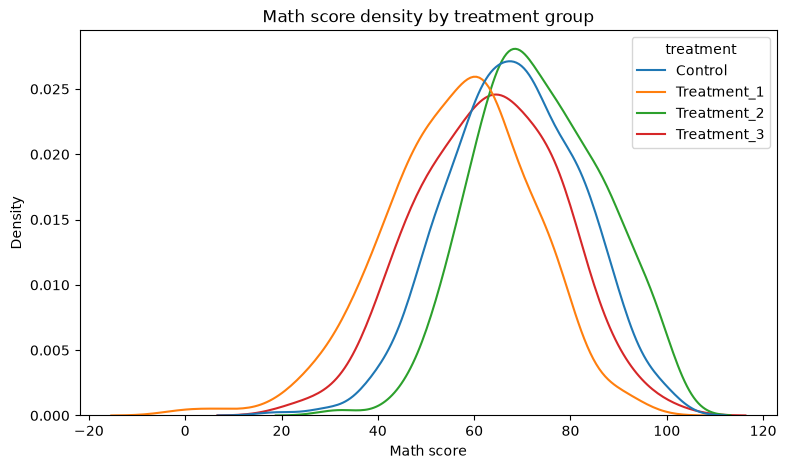

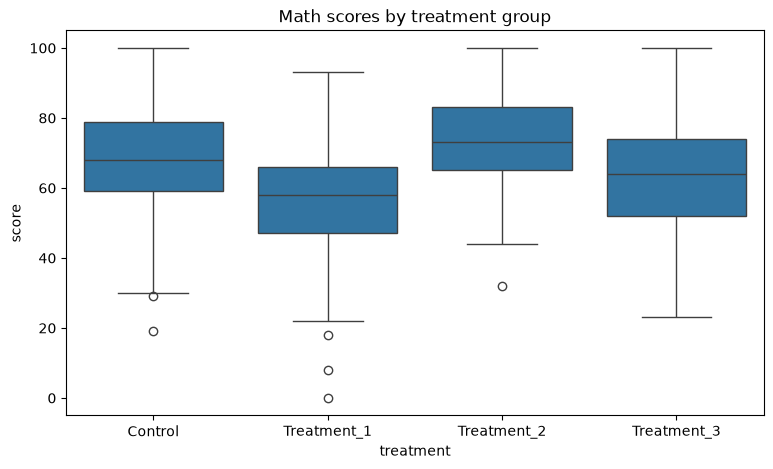

In [28]:
## TODO: Create a density plot to compare the scores by treatment type.
plt.figure(figsize=(9, 5))
sns.kdeplot(data=treatments_df, x='score', hue='treatment', common_norm=False)
plt.title('Math score density by treatment group')
plt.xlabel('Math score')
plt.show()

plt.figure(figsize=(9, 5))
sns.boxplot(data=treatments_df, x='treatment', y='score')
plt.title('Math scores by treatment group')
plt.show()

</br>
</br>
</br>

Each group looks pretty normal , but let's perform some tests to be sure:

> **My note:** in the density plot all four groups look roughly bell-shaped. Control and Treatment_2 (test preparation only) sit more to the right, and Treatment_1 (free/reduced lunch only) sits most to the left.

In [29]:
## TODO: Perform normality tests for each group using Shapiro-Wilk and Lilliefors tests.
# H0 for both tests: the scores of the group are normally distributed.
treatment_groups = {name: group['score'] for name, group in treatments_df.groupby('treatment')}
for name, scores in treatment_groups.items():
    shapiro_p = stats.shapiro(scores).pvalue
    lillie_p = lilliefors(scores, dist='norm')[1]
    print(f"{name:<12} n = {len(scores):<4} Shapiro-Wilk p = {shapiro_p:.4f}   Lilliefors p = {lillie_p:.4f}")

Control      n = 418  Shapiro-Wilk p = 0.2223   Lilliefors p = 0.1202
Treatment_1  n = 224  Shapiro-Wilk p = 0.0521   Lilliefors p = 0.1332
Treatment_2  n = 227  Shapiro-Wilk p = 0.0514   Lilliefors p = 0.0837
Treatment_3  n = 131  Shapiro-Wilk p = 0.9540   Lilliefors p = 0.6179


**Normality is checked for each treatment group!**

- Similarity of variances

> **My note:** all eight p-values are above 0.05. Shapiro-Wilk: Control 0.2223, Treatment_1 0.0521, Treatment_2 0.0514, Treatment_3 0.9540. Lilliefors: 0.1202, 0.1332, 0.0837, 0.6179. Treatment_1 and Treatment_2 are close to the limit with Shapiro-Wilk, but I don't reject normality at 0.05.

In [30]:
## TODO: Check for the similarity of variances using rough rules and perform Bartlett's and Fligner tests.
group_variances = {name: scores.var() for name, scores in treatment_groups.items()}
for name, variance in group_variances.items():
    print(f"Variance {name:<12}: {variance:.2f}")
largest_ratio = max(group_variances.values()) / min(group_variances.values())
print(f"Rough rule: largest / smallest variance = {largest_ratio:.3f} (below 2 is OK)")

# H0 for both tests: all the groups have the same variance.
bartlett_stat, bartlett_p = stats.bartlett(*treatment_groups.values())
fligner_stat, fligner_p = stats.fligner(*treatment_groups.values())
print(f"Bartlett test: statistic = {bartlett_stat:.4f}, p-value = {bartlett_p:.4f}")
print(f"Fligner test:  statistic = {fligner_stat:.4f}, p-value = {fligner_p:.4f}")

Variance Control     : 185.77
Variance Treatment_1 : 227.69
Variance Treatment_2 : 169.47
Variance Treatment_3 : 208.09
Rough rule: largest / smallest variance = 1.344 (below 2 is OK)
Bartlett test: statistic = 5.6925, p-value = 0.1276
Fligner test:  statistic = 2.9855, p-value = 0.3939


**Homogeneity of variances of treatment groups is checked!** ( both with a rough rule and with actual tests.)

We can finally perform ANOVA:

> **My note:** the largest / smallest variance ratio is 1.344 (below 2). Bartlett p = 0.1276 and Fligner p = 0.3939, both above 0.05, so I don't reject equal variances.

In [31]:
## TODO: Perform ANOVA to check if there's a significant difference between the groups.
# H0: all four group means are the same. H_A: at least one mean is different.
f_value, anova_p_value = stats.f_oneway(*treatment_groups.values())
print(f"F-value = {f_value:.4f}")
print(f"p-value = {anova_p_value:.3e}")
print("Reject H0" if anova_p_value < 0.05 else "Fail to reject H0", "at alpha = 0.05")

F-value = 61.9072
p-value = 1.053e-36
Reject H0 at alpha = 0.05


### Key takeaways:


- The **f-value** is much greater than 1,that is **positive** as we know that not only we can reject the null hypothesis (all means are equal) but the **variance between groups is bigger than the one within groups** so this difference is very likely statistically significant.

- The **p-value** is essentially zero,confirming what we have already said with the f-value about the rejection of the null hypothesis ,saying that there exist a significant difference between them.


### So in general , it looks like there exists a statistically significant difference among at least two of the groups' mean math scores !

But wait... which couples of means are different from each other?

To answer this question we must perform a post-hoc test.

### Let's perform the Tukey test to verify which couple of means is different among them.

> **My note:** my ANOVA gives **F = 61.91** and **p ≈ 1.05e-36**, so I reject H0. The group means are: Control 68.13 (n = 418), Treatment_1 56.51 (n = 224), Treatment_2 73.53 (n = 227), Treatment_3 63.05 (n = 131).

### Key takeaways:

- As the boxplot already showed , the difference in means between treatment 1 and control , with control group having higher math scores , is significant: **it looks like having the economic freedom of not paying or paying less for lunch negatively impats math scores!**

- Another important difference already present in the boxplot , the difference in means between treatment 2 and 1 , with treatment 2 having higher math scores , is significant:  **only attending the test preparation course and not having the economic freedom of the free or reduced lunch is more effective than having that economic freedom and not attending the test preparation course!**

- This difference was also present in the boxplot , like the other two , and is between the third and second treatments, with treatment two being more effective than the third.
This means that : **the people who attended the test preparation course but also enjoyed the economic freedom of the free/reduced lunch , statistically perform worse than people who have attened the test , but have to pay for lunch**.

### Conclusions : from these tests it looks like , while on the one hand saving the lunch money has a negative effect on math scores as opposed as we expected , on the other hand attending the test preparation course has a positive one as we expected.

### Maybe people used the money saved from lunch to buy things that distracted them from studying maths! That's not good , buy more math books with that money!

> **My note:** this template has no code cell for the Tukey test, so I didn't run it. The group means from my run point the same way as these takeaways: Control (68.13) is higher than Treatment_1 (56.51), Treatment_2 (73.53) is higher than Treatment_1, and Treatment_2 is higher than Treatment_3 (63.05). Without Tukey I can't say exactly which pairs are significant, only that at least one pair is (ANOVA p ≈ 1.05e-36). Also, free/reduced lunch is usually given to students from lower-income families, so the lower math scores are more likely linked to that background than *caused* by the lunch itself.